In [23]:
import pandas as pd

# Load CSV
data = pd.read_csv("data/Indoor Air Pollution Data.csv", low_memory=False)
data.describe()

,NH3,CO,PM2.5,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17
count,173465.000000,173465.000000,173465.000000,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.0,1.00
mean,0.670185,4.339625,0.057456,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
std,0.177971,1.615590,0.116102,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.290000,0.290000,0.000000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
25%,0.540000,3.610000,0.000000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
50%,0.650000,4.190000,0.000000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
75%,0.750000,4.860000,0.000000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45
max,1.630000,9.920000,0.470000,4.59,0.33,29.18,943.68,595.99,38.59,400.0,0.0,12.45


In [24]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 173468 entries, 0 to 173467
Data columns (total 19 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   NH3          173465 non-null  float64
 1   NO2          173468 non-null  object 
 2   CO           173465 non-null  float64
 3   PM2.5        173465 non-null  float64
 4   Temp         173465 non-null  object 
 5   Pressure     173465 non-null  object 
 6   Humidity     173465 non-null  object 
 7   O3           173465 non-null  object 
 8   Date         173465 non-null  object 
 9   Unnamed: 9   1 non-null       float64
 10  Unnamed: 10  1 non-null       float64
 11  Unnamed: 11  1 non-null       float64
 12  Unnamed: 12  1 non-null       float64
 13  Unnamed: 13  1 non-null       float64
 14  Unnamed: 14  1 non-null       float64
 15  Unnamed: 15  1 non-null       float64
 16  Unnamed: 16  1 non-null       float64
 17  Unnamed: 17  1 non-null       float64
 18  Unnamed: 18  1 non-null 

In [25]:
# Drop unnamed columns
data.drop(columns=[col for col in data.columns if "Unnamed" in col], inplace=True)

In [11]:
data.dropna(inplace=True)
# Remove duplicate rows if any
data = data.drop_duplicates()
# Fix numeric columns with bad characters (like '12.450.73')
for col in data.columns[:-1]:  # skip 'Date' column
    data[col] = data[col].astype(str).str.replace('[^0-9.]', '', regex=True)
    data[col] = data[col].apply(lambda x: x if x.count('.') <= 1 else x.replace('.', '', x.count('.') - 1))  # keep last dot
    data[col] = pd.to_numeric(data[col], errors='coerce')

In [27]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
NH3         3
CO          3
PM2.5       3
Temp        3
Pressure    3
Humidity    3
O3          3
Date        3
dtype: int64


In [28]:
data = data.set_index('Date')

In [29]:

# Constants
R = 0.08205  # Ideal gas constant in (L·atm)/(mol·K)
MW = {
    'CO': 28.01,    # Carbon Monoxide in ppm
    'NO2': 46.01,   # Nitrogen Dioxide in ppm
    'NH3': 17.03,   # Ammonia in ppm
    'O3': 48.00     # Ozone in ppb
}

# Conversion functions
def ppm_to_ugm3(ppm, mw, temp_c, pressure_hpa):
    pressure_atm = pressure_hpa / 1013.25
    return (ppm * mw * pressure_atm * 1000) / (R * (temp_c + 273.15))

def ppb_to_ugm3(ppb, mw, temp_c, pressure_hpa):
    pressure_atm = pressure_hpa / 1013.25
    return (ppb * mw * pressure_atm) / (R * (temp_c + 273.15))

# Ensure relevant columns are numeric
for col in ['CO', 'NO2', 'NH3', 'O3', 'Temp', 'Pressure']:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Apply conversions
data['CO_ugm3'] = ppm_to_ugm3(data['CO'], MW['CO'], data['Temp'], data['Pressure'])
data['NO2_ugm3'] = ppm_to_ugm3(data['NO2'], MW['NO2'], data['Temp'], data['Pressure'])
data['NH3_ugm3'] = ppm_to_ugm3(data['NH3'], MW['NH3'], data['Temp'], data['Pressure'])
data['O3_ugm3'] = ppb_to_ugm3(data['O3'], MW['O3'], data['Temp'], data['Pressure'])


In [30]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
NH3            3
NO2            3
CO             3
PM2.5          3
Temp        3529
Pressure    3528
Humidity       3
O3             4
CO_ugm3     3529
NO2_ugm3    3529
NH3_ugm3    3529
O3_ugm3     3530
dtype: int64


In [31]:
# --- Define EAQI breakpoints for each pollutant (in µg/m³) ---
eaqi_breakpoints = {
    'PM2.5': [
        (0.0, 50.4, 0, 50),
        (50.5, 60.4, 51, 100),
        (60.5, 75.4, 101, 150),
        (75.5, 150.4, 151, 200),
        (150.5, 250.4, 201, 300),
        (250.5, 500.4, 301, 500)
    ],
    'CO_ugm3': [  # Converted from mg/m³ to µg/m³
        (0.0, 5400.0, 0, 50),
        (5401.0, 10400.0, 51, 100),
        (10401.0, 14400.0, 101, 150),
        (14401.0, 17900.0, 151, 200),
        (17901.0, 35400.0, 201, 300),
        (35401.0, 58400.0, 301, 500)
    ],
    'NO2_ugm3': [
        (0.0, 100.0, 0, 50),
        (101.0, 400.0, 51, 100),
        (401.0, 677.0, 101, 150),
        (678.0, 1221.0, 151, 200),
        (1222.0, 2349.0, 201, 300),
        (2350.0, 3853.0, 301, 500)
    ],
    'O3_ugm3': [
        (0.0, 100.0, 0, 50),
        (101.0, 400.0, 51, 100),
        (401.0, 677.0, 101, 150),
        (678.0, 1221.0, 151, 200),
        (1222.0, 2349.0, 201, 300),
        (2350.0, 3853.0, 301, 500)
    ]
}

# --- Function to calculate sub-index for a given pollutant ---
def calculate_eaqi_sub_index(value, breakpoints):
    for BPLo, BPHi, ILo, IHi in breakpoints:
        if BPLo <= value <= BPHi:
            return round(((IHi - ILo) / (BPHi - BPLo)) * (value - BPLo) + ILo)
    return None

# --- Calculate EAQI sub-indices ---
data['EAQI_PM25'] = data['PM2.5'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['PM2.5']))
data['EAQI_CO'] = data['CO_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['CO_ugm3']))
data['EAQI_NO2'] = data['NO2_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['NO2_ugm3']))
data['EAQI_O3'] = data['O3_ugm3'].apply(lambda x: calculate_eaqi_sub_index(x, eaqi_breakpoints['O3_ugm3']))

# --- Final EAQI is the max sub-index across pollutants ---
data['EAQI_Overall'] = data[['EAQI_PM25', 'EAQI_CO', 'EAQI_NO2', 'EAQI_O3']].max(axis=1)

# --- Classify into EAQI categories ---
def classify_eaqi(index_value):
    if pd.isna(index_value):
        return None
    elif index_value <= 50:
        return "Good"
    elif index_value <= 100:
        return "Moderate"
    elif index_value <= 150:
        return "Unhealthy for sensitive groups"
    elif index_value <= 200:
        return "Unhealthy"
    elif index_value <= 300:
        return "Very unhealthy"
    elif index_value <= 500:
        return "Hazardous"
    else:
        return "Out of Range"

data['EAQI_Category'] = data['EAQI_Overall'].apply(classify_eaqi)


In [32]:
# Count each EAQI category
category_counts = data['EAQI_Category'].value_counts().sort_index()

# Format as a table
print("\n📊 EAQI Category Distribution (based on max pollutant per record):\n")
print("| EAQI Category                     | Count     |")
print("|----------------------------------|-----------|")
for category, count in category_counts.items():
    print(f"| {category:<32} | {count:<9} |")


📊 EAQI Category Distribution (based on max pollutant per record):

| EAQI Category                     | Count     |
|----------------------------------|-----------|
| Good                             | 3561      |
| Hazardous                        | 43        |
| Moderate                         | 151208    |
| Unhealthy                        | 2792      |
| Unhealthy for sensitive groups   | 15720     |
| Very unhealthy                   | 141       |


In [33]:
# Check for missing values
missing_counts = data.isnull().sum()

# Filter only columns that have missing values
missing_counts = missing_counts[missing_counts > 0]

# Show result
print("Columns with missing values:")
print(missing_counts)

Columns with missing values:
NH3                 3
NO2                 3
CO                  3
PM2.5               3
Temp             3529
Pressure         3528
Humidity            3
O3                  4
CO_ugm3          3529
NO2_ugm3         3529
NH3_ugm3         3529
O3_ugm3          3530
EAQI_PM25           3
EAQI_CO          3540
EAQI_NO2         3581
EAQI_O3          3615
EAQI_Overall        3
EAQI_Category       3
dtype: int64


In [36]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder

  # Replace with your actual file path

# 2. Identify features and target
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
target = 'EAQI_Category'

# 3. Drop columns not needed for training (like EAQI_CO, EAQI_NO2, EAQI_O3)
drop_cols = ['EAQI_CO', 'EAQI_NO2', 'EAQI_O3']
data.drop(columns=[col for col in drop_cols if col in data.columns], inplace=True)

# 4. Check missing values
print("Missing value count:\n", data[features + [target]].isnull().sum())

# 5. Drop rows where target is missing (classification label must be known)
data = data.dropna(subset=[target])

# 6. Impute missing feature values with mean
imputer = SimpleImputer(strategy='mean')
data[features] = imputer.fit_transform(data[features])



# 8. Check if it worked
print("\n✅ Final check: No missing values?\n", data.isnull().sum().sum() == 0)
print("🟢 Class distribution after cleaning:\n", data[target].value_counts())


Missing value count:
 PM2.5            0
CO_ugm3          0
NO2_ugm3         0
NH3_ugm3         0
O3_ugm3          0
Temp             0
Humidity         0
Pressure         0
EAQI_Category    0
dtype: int64

✅ Final check: No missing values?
 False
🟢 Class distribution after cleaning:
 EAQI_Category
Moderate                          151208
Unhealthy for sensitive groups     15720
Good                                3561
Unhealthy                           2792
Very unhealthy                       141
Hazardous                             43
Name: count, dtype: int64


In [35]:
# iaq_model_training_balanced.py

import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# 1. Load your data


# 2. Subsample 'Moderate' class to 10,000 rows
balanced_data = (
    pd.concat([
        data[data['EAQI_Category'] == 'Moderate'].sample(n=10000, random_state=42),
        data[data['EAQI_Category'] != 'Moderate']
    ])
    .sample(frac=1, random_state=42)  # Shuffle the rows
)

# 3. Prepare features and target
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = balanced_data[features]
y = balanced_data['EAQI_Category']

# 4. Encode target labels
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 5. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# 6. Build pipeline: SMOTE + Scaling + Classifier
pipeline = ImbPipeline(steps=[
    ('smote', SMOTE(random_state=42)),
    ('scaler', StandardScaler()),
    ('clf', GradientBoostingClassifier(random_state=42))
])

# 7. Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X_train, y_train, scoring='f1_macro', cv=cv)
print(f"CV Macro F1: {np.mean(scores):.4f} ± {np.std(scores):.4f}")

# 8. Train final model
pipeline.fit(X_train, y_train)

# 9. Evaluate
y_pred = pipeline.predict(X_test)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 10. Save model and encoder
joblib.dump(pipeline, "best_model_pipeline02.pkl")
joblib.dump(le, "label_encoder02.pkl")


CV Macro F1: 0.9941 ± 0.0076

Classification Report:

                                precision    recall  f1-score   support

                          Good       1.00      1.00      1.00       712
                     Hazardous       1.00      0.89      0.94         9
                      Moderate       1.00      1.00      1.00      2000
                     Unhealthy       1.00      1.00      1.00       559
Unhealthy for sensitive groups       1.00      1.00      1.00      3144
                Very unhealthy       0.97      1.00      0.98        28

                      accuracy                           1.00      6452
                     macro avg       0.99      0.98      0.99      6452
                  weighted avg       1.00      1.00      1.00      6452



['label_encoder02.pkl']

In [38]:
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report
from sklearn.ensemble import GradientBoostingClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Load data

data.dropna(subset=['EAQI_Category'], inplace=True)
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
data.dropna(subset=features, inplace=True)

X = data[features]
y = data['EAQI_Category']

# Encode target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# Split
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42)

# Updated: Apply scaler before SMOTE
pipeline = ImbPipeline(steps=[
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('clf', GradientBoostingClassifier(random_state=42))
])

# Cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipeline, X_train, y_train, scoring='f1_macro', cv=cv)
print(f"CV Macro F1: {np.mean(scores):.4f} ± {np.std(scores):.4f}")

# Final training
pipeline.fit(X_train, y_train)

# Evaluate
y_pred = pipeline.predict(X_test)
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Save
joblib.dump(pipeline, 'best_model_pipeline04.pkl')
joblib.dump(le, 'label_encoder04.pkl')


CV Macro F1: 0.9984 ± 0.0029
                                precision    recall  f1-score   support

                          Good       1.00      1.00      1.00       712
                     Hazardous       0.82      1.00      0.90         9
                      Moderate       1.00      1.00      1.00     30242
                     Unhealthy       1.00      1.00      1.00       558
Unhealthy for sensitive groups       1.00      1.00      1.00      3144
                Very unhealthy       1.00      0.96      0.98        28

                      accuracy                           1.00     34693
                     macro avg       0.97      0.99      0.98     34693
                  weighted avg       1.00      1.00      1.00     34693



['label_encoder04.pkl']


🔄 Training & Evaluating: Logistic Regression
💾 Saved model: trained_models/Logistic_Regression.pkl

🔄 Training & Evaluating: Ridge Classifier
💾 Saved model: trained_models/Ridge_Classifier.pkl

🔄 Training & Evaluating: Linear SVM
💾 Saved model: trained_models/Linear_SVM.pkl

🔄 Training & Evaluating: Random Forest
💾 Saved model: trained_models/Random_Forest.pkl

🔄 Training & Evaluating: Gradient Boosting
💾 Saved model: trained_models/Gradient_Boosting.pkl

🔄 Training & Evaluating: XGBoost
💾 Saved model: trained_models/XGBoost.pkl

🔄 Training & Evaluating: KNN
💾 Saved model: trained_models/KNN.pkl

🔄 Training & Evaluating: Nearest Centroid
💾 Saved model: trained_models/Nearest_Centroid.pkl

🔄 Training & Evaluating: MLP Classifier
💾 Saved model: trained_models/MLP_Classifier.pkl

🔄 Training & Evaluating: Naive Bayes
💾 Saved model: trained_models/Naive_Bayes.pkl

🔄 Training & Evaluating: LightGBM
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.00388

/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003654 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 580638, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003648 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 580638, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759


...

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003686 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 580638, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004005 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 580638, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


/Users/anugrahaantoo/Desktop/Final Project /Indoor_Air_Quality_Prediction/venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004945 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2040
[LightGBM] [Info] Number of data points in the train set: 725796, number of used features: 8
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Info] Start training from score -1.791759
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
💾 Saved model: trained_models/LightGBM.pkl

🔄 Training & Evaluating: CatBoost
💾 Saved model: trained_models/CatBoost.pkl

📊 Model Performance Summary:
                     C

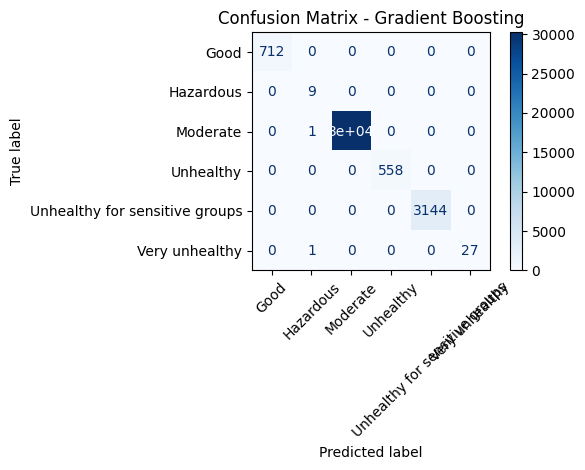

['label_encoder.pkl']

In [39]:
# 1. Import Libraries
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestCentroid
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import joblib

# Optional: LightGBM and CatBoost
has_lightgbm = has_catboost = True
try:
    from lightgbm import LGBMClassifier
except ImportError:
    print("⚠️ LightGBM not installed.")
    has_lightgbm = False
try:
    from catboost import CatBoostClassifier
except ImportError:
    print("⚠️ CatBoost not installed.")
    has_catboost = False

# 2. Load and Prepare Data (Assumes you already have `data`)
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = data[features]
y = data['EAQI_Category']

# 3. Encode Target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 4. Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

# 5. Define Classifiers
model_defs = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight='balanced'),
    "Ridge Classifier": RidgeClassifier(class_weight='balanced'),
    "Linear SVM": LinearSVC(max_iter=10000, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(class_weight='balanced', random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric='mlogloss', random_state=42),
    "KNN": KNeighborsClassifier(),
    "Nearest Centroid": NearestCentroid(),
    "MLP Classifier": MLPClassifier(random_state=42, max_iter=300),
    "Naive Bayes": GaussianNB()
}

if has_lightgbm:
    model_defs["LightGBM"] = LGBMClassifier(class_weight='balanced', random_state=42)
if has_catboost:
    model_defs["CatBoost"] = CatBoostClassifier(verbose=0, random_state=42)

# 6. Create Pipelines
models = {}
for name, clf in model_defs.items():
    steps = [('scaler', StandardScaler()), ('smote', SMOTE(random_state=42)), ('clf', clf)]
    models[name] = ImbPipeline(steps)

# 7. Train, Evaluate, and Save All Models
results = {}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
os.makedirs("trained_models", exist_ok=True)

for name, pipe in models.items():
    print(f"\n🔄 Training & Evaluating: {name}")
    f1_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1_macro')
    results[name] = {
        "CV Macro F1 (mean)": round(np.mean(f1_scores), 4),
        "CV Macro F1 (std)": round(np.std(f1_scores), 4)
    }
    pipe.fit(X_train, y_train)
    joblib.dump(pipe, f"trained_models/{name.replace(' ', '_')}.pkl")
    print(f"💾 Saved model: trained_models/{name.replace(' ', '_')}.pkl")

# 8. Show Summary Table
results_df = pd.DataFrame(results).T.sort_values(by="CV Macro F1 (mean)", ascending=False)
print("\n📊 Model Performance Summary:")
print(results_df)

# 9. Final Evaluation on Best Model
best_model_name = results_df.index[0]
print(f"\n✅ Final Evaluation on Best Model: {best_model_name}")
best_model = models[best_model_name]
y_pred = best_model.predict(X_test)

print("\n🧾 Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Extra metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average='macro')
rec = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')
mae = mean_absolute_error(y_test, y_pred)

print(f"\n📈 Accuracy: {acc:.4f}")
print(f"📏 Precision (macro): {prec:.4f}")
print(f"📊 Recall (macro): {rec:.4f}")
print(f"⭐ F1-score (macro): {f1:.4f}")
print(f"🧮 MAE: {mae:.4f}")

# 10. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=le.classes_, xticks_rotation=45, cmap='Blues'
)
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

# 11. Save Best Model and Label Encoder
joblib.dump(best_model, "best_model_pipeline.pkl")
joblib.dump(le, "label_encoder.pkl")


In [40]:
import os
import pandas as pd
import numpy as np
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, mean_absolute_error

# 1. TabNet
from pytorch_tabnet.tab_model import TabNetClassifier

# 2. AutoGluon
from autogluon.tabular import TabularPredictor

# --------------------------
# Step 1: Load and preprocess
# --------------------------
features = ['PM2.5', 'CO_ugm3', 'NO2_ugm3', 'NH3_ugm3', 'O3_ugm3', 'Temp', 'Humidity', 'Pressure']
X = data[features]
y = data['EAQI_Category']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, stratify=y_encoded, test_size=0.2, random_state=42)

# Save encoders
os.makedirs("trained_models", exist_ok=True)
joblib.dump(le, "trained_models/label_encoder.pkl")
joblib.dump(features, "trained_models/feature_names.pkl")

# --------------------------
# Step 2: Train TabNet
# --------------------------
X_tabnet = X_train.values
y_tabnet = y_train.reshape(-1, 1)
X_test_tabnet = X_test.values

tabnet_clf = TabNetClassifier(verbose=0)
tabnet_clf.fit(X_tabnet, y_tabnet, max_epochs=100, patience=10, eval_metric=['accuracy'])

y_pred_tabnet = tabnet_clf.predict(X_test_tabnet).reshape(-1)
tabnet_metrics = classification_report(y_test, y_pred_tabnet, target_names=le.classes_, output_dict=True)

# Save model
tabnet_clf.save_model("trained_models/TabNet_model")

# --------------------------
# Step 3: Train AutoGluon
# --------------------------
ag_train = X_train.copy()
ag_train['label'] = le.inverse_transform(y_train)  # AutoGluon needs labels as strings

predictor = TabularPredictor(label='label', path="trained_models/AutoGluon_model").fit(ag_train)

y_pred_ag = predictor.predict(X_test)
y_pred_ag_encoded = le.transform(y_pred_ag)
autogluon_metrics = classification_report(y_test, y_pred_ag_encoded, target_names=le.classes_, output_dict=True)

# --------------------------
# Step 4: Show Metrics Summary
# --------------------------
def summarize_metrics(name, metrics_dict):
    return {
        "Model": name,
        "Accuracy": round(metrics_dict['accuracy'], 4),
        "Precision": round(metrics_dict['macro avg']['precision'], 4),
        "Recall": round(metrics_dict['macro avg']['recall'], 4),
        "F1-Score": round(metrics_dict['macro avg']['f1-score'], 4)
    }

summary_df = pd.DataFrame([
    summarize_metrics("TabNet", tabnet_metrics),
    summarize_metrics("AutoGluon", autogluon_metrics)
]).set_index("Model")

summary_df


ModuleNotFoundError: No module named 'autogluon'